# Uber Driving Performance – Data Visualisation

This notebook presents the key findings from the exploratory data analysis of Uber trips in Dubrovnik during the 2024 and 2025 tourist seasons.

The visualisations focus on identifying the most promising driving hours, days, and external conditions for maximizing recorded Uber fare earnings.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv(
    '../../data/processed_data/uber_analysis_ready.csv'
)

df['start_time_local'] = pd.to_datetime(df['start_time_local'])
df['ride_date'] = pd.to_datetime(df['ride_date'])

df.shape

(1334, 20)

## 1. Hourly Ride Activity

Distribution of completed Uber rides by starting hour across the 2024 and 2025 datasets.

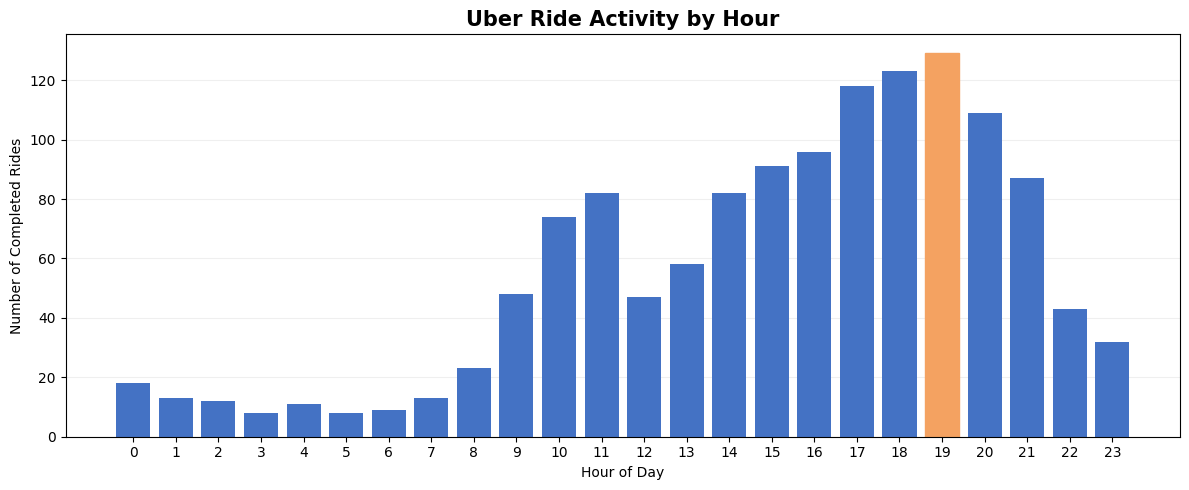

In [10]:
hourly_rides = (
    df.groupby('hour_of_day')
    .size()
    .reindex(range(24), fill_value=0)
)

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    hourly_rides.index,
    hourly_rides.values,
    color='#4472C4'
)

peak_hour = hourly_rides.idxmax()
bars[peak_hour].set_color('#F4A261')

ax.set_title('Uber Ride Activity by Hour', fontsize=15, weight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Number of Completed Rides')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('01_hourly_ride_activity.png', dpi=300, bbox_inches='tight')
plt.show()

#### Key Insight

Uber ride activity was highest during the late afternoon and evening, peaking at 19:00. A noticeable increase in completed rides occurred from approximately 14:00 onwards.

However, these results reflect the driver’s recorded activity rather than overall market demand, as the dataset does not include hours spent online without completed trips.

Therefore, ride frequency alone cannot determine the most profitable driving hours.

## 2. Average Uber Fare by Hour

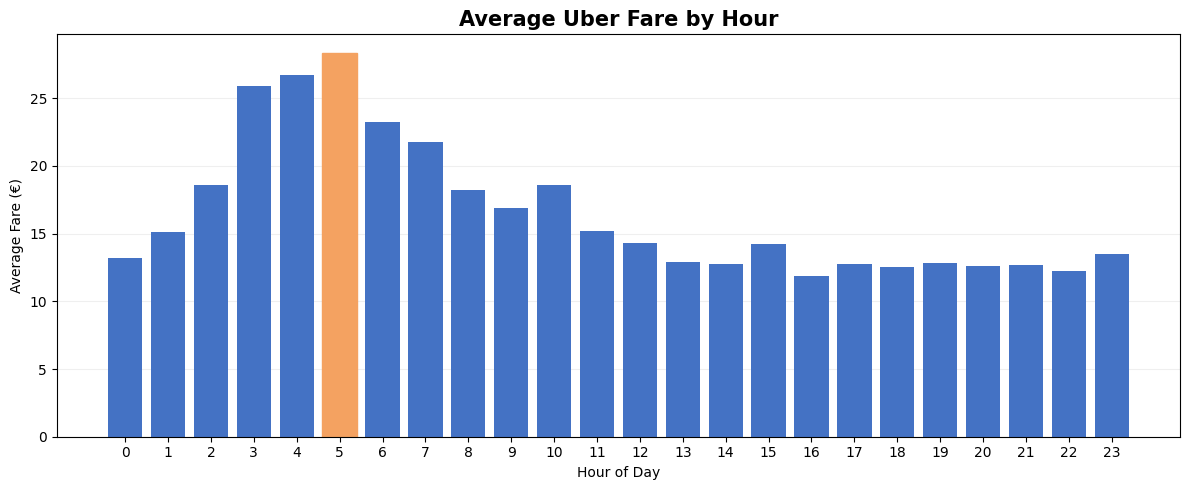

In [11]:
hourly_avg_fare = (
    df.groupby('hour_of_day')['original_fare']
    .mean()
    .reindex(range(24))
)

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    hourly_avg_fare.index,
    hourly_avg_fare.values,
    color='#4472C4'
)

peak_hour = hourly_avg_fare.idxmax()

bars[int(peak_hour)].set_color('#F4A261')

ax.set_title('Average Uber Fare by Hour', fontsize=15, weight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Average Fare (€)')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('02_average_fare_by_hour.png', dpi=300, bbox_inches='tight')
plt.show()

#### Key Insight

The highest average Uber fare was recorded at approximately 04:00, reaching around €29 per trip. Early-morning hours between 02:00 and 05:00 consistently showed higher average fares compared with most daytime and evening hours.

In contrast, the highest number of completed rides occurred at 19:00, demonstrating that higher ride frequency does not necessarily correspond to higher average fares.

##### Based on the driver’s firsthand operational experience in Dubrovnik, these elevated early-morning fares are strongly associated with airport transfers, early flight schedules, and Uber’s dynamic pricing algorithm, which increases fares during periods of high demand relative to driver availability.

During these hours, airport transportation demand combined with potentially lower driver availability can contribute to higher trip prices.

However, this explanation could not be independently validated through statistical analysis because historical flight arrival and departure data were unavailable due to paid API access.

Therefore, the relationship between flight activity and elevated early-morning fares is supported by operational experience but remains unverified within the available dataset.

Additionally, the relatively small number of recorded trips during these hours should be considered when interpreting the results.

## 3. Driving Performance by Day and Time Block
Average total recorded Uber fares per active day, grouped by day of the week and four-hour driving periods.

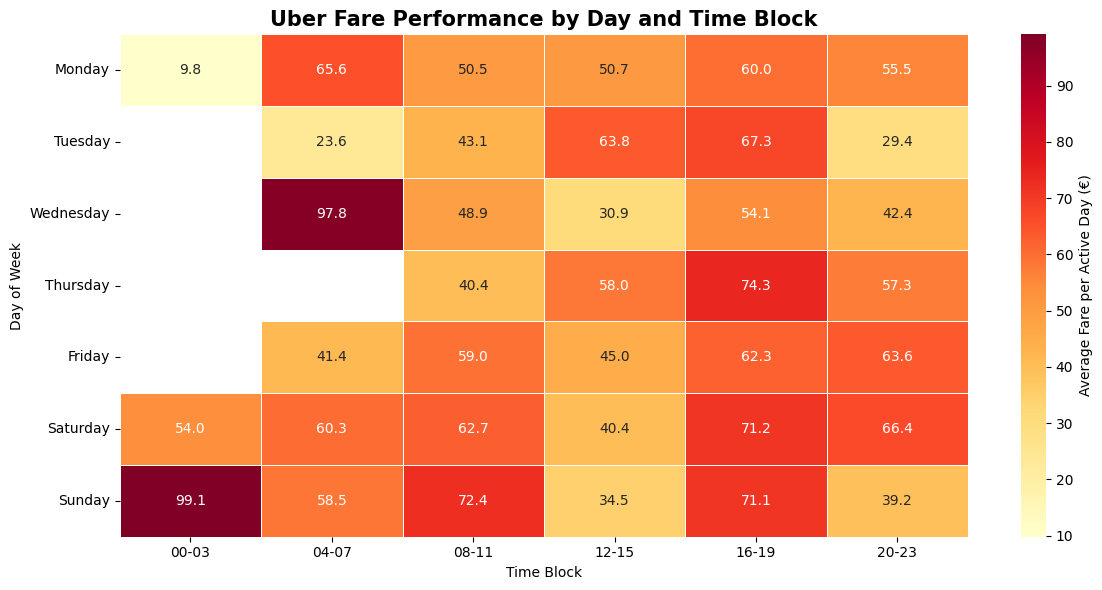

In [12]:
df['time_block'] = pd.cut(
    df['hour_of_day'],
    bins=[-1, 3, 7, 11, 15, 19, 23],
    labels=['00-03', '04-07', '08-11',
            '12-15', '16-19', '20-23']
)

daily_block_fares = (
    df.groupby(
        ['day_of_week', 'time_block', 'ride_date'],
        observed=True
    )['original_fare']
    .sum()
    .reset_index()
)

heatmap_data = (
    daily_block_fares.groupby(
        ['day_of_week', 'time_block'],
        observed=True
    )['original_fare']
    .mean()
    .unstack()
)

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

heatmap_data = heatmap_data.reindex(day_order)

plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Average Fare per Active Day (€)'}
)

plt.title(
    'Uber Fare Performance by Day and Time Block',
    fontsize=15,
    weight='bold'
)

plt.xlabel('Time Block')
plt.ylabel('Day of Week')

plt.tight_layout()
plt.savefig('03_driving_performance_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

#### Key Insight

The heatmap highlights substantial differences in recorded Uber fare performance across days of the week and four-hour time blocks.

Sunday between 00:00 and 03:59 recorded the highest average fare total per active day (€99.11), followed by Wednesday between 04:00 and 07:59 (€97.80).

Late-afternoon periods also demonstrated promising performance, particularly Thursday (€74.30) and Saturday (€71.20) between 16:00 and 19:59.

Based on the driver’s operational experience, early-morning airport transfers and Uber’s dynamic pricing may help explain the stronger performance during certain overnight periods. However, this relationship could not be statistically verified without historical flight data.

Important limitation: These values represent average recorded Uber fares per active calendar day within each time block, not actual hourly or net earnings. The dataset does not capture the driver’s full online working hours, waiting time, or trips completed through other platforms.

Empty cells indicate combinations without recorded Uber trips, rather than zero market demand.

## Weather Impact on Uber Fare Performance
Comparison of average Uber trip fares under rainy and dry weather conditions.

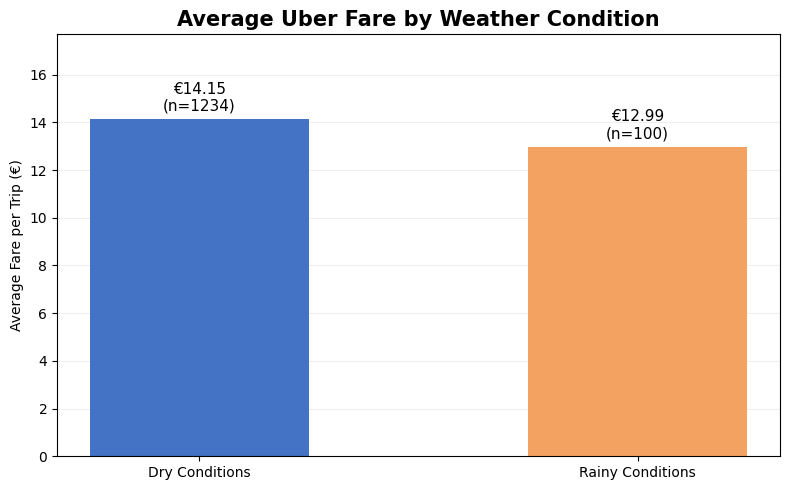

In [13]:
weather_fares = (
    df.groupby('is_raining')['original_fare']
    .agg(['mean', 'count'])
    .reindex([False, True])
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ['Dry Conditions', 'Rainy Conditions'],
    weather_fares['mean'],
    color=['#4472C4', '#F4A261'],
    width=0.5
)

for bar, count in zip(bars, weather_fares['count']):
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f'€{height:.2f}\n(n={int(count)})',
        ha='center',
        va='bottom',
        fontsize=11
    )

ax.set_title(
    'Average Uber Fare by Weather Condition',
    fontsize=15,
    weight='bold'
)

ax.set_ylabel('Average Fare per Trip (€)')
ax.set_ylim(0, weather_fares['mean'].max() * 1.25)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('04_weather_impact.png', dpi=300, bbox_inches='tight')
plt.show()

#### Key Insight

Uber trips recorded during dry weather conditions had an average fare of €14.15, compared with €12.99 during rainy conditions, representing approximately an 8.2% difference.

Although rainfall might be expected to increase demand for transportation services, the observed data did not show higher average fares during rainy periods.

However, the dataset contains substantially fewer trips during rainy conditions (100) compared with dry conditions (1,234).

These findings suggest that rainfall alone is not a reliable indicator of higher Uber trip fares within the observed dataset. Other factors, including trip distance, time of day, seasonal patterns, and driver availability, may influence the results.

The analysis identifies an association rather than establishing a causal relationship between weather conditions and fare values.

## 5. Cruise Ship Arrivals and Uber Fare Performance

Comparison of average Uber trip fares with and without cruise ship arrivals during the preceding three hours.

In [6]:
# Load hourly cruise arrivals
cruise = pd.read_csv(
    '../../data/processed_data/cruise_hourly_cleaned.csv'
)

cruise['arrival_datetime'] = pd.to_datetime(
    cruise['arrival_datetime']
)

cruise.head()

,arrival_datetime,cruise_count_hourly,cruise_count_daily
0,2024-04-22 20:00:00,1,1
1,2024-04-23 07:00:00,1,1
2,2024-04-24 06:00:00,1,3
3,2024-04-24 07:00:00,2,3
4,2024-04-25 08:00:00,1,1


In [7]:
# Aggregate cruise arrivals by hour
cruise_hourly = (
    cruise.groupby('arrival_datetime')['cruise_count_hourly']
    .sum()
)

# Convert ride timestamps to hourly timestamps
df['ride_hour'] = df['start_time_local'].dt.floor('h')

# Count cruise arrivals in the preceding 3 hours
df['cruises_previous_3h'] = sum(
    df['ride_hour'].sub(pd.Timedelta(hours=h))
    .map(cruise_hourly).fillna(0)
    for h in [1, 2, 3]
)

# Compare average fares
cruise_comparison = (
    df.groupby(df['cruises_previous_3h'] > 0)['original_fare']
    .agg(['mean', 'count'])
)

cruise_comparison.index = [
    'No Recent Cruise Arrival',
    'Cruise Arrival in Previous 3h'
]

cruise_comparison.round(2)

,mean,count
No Recent Cruise Arrival,13.81,1107
Cruise Arrival in Previous 3h,15.33,227


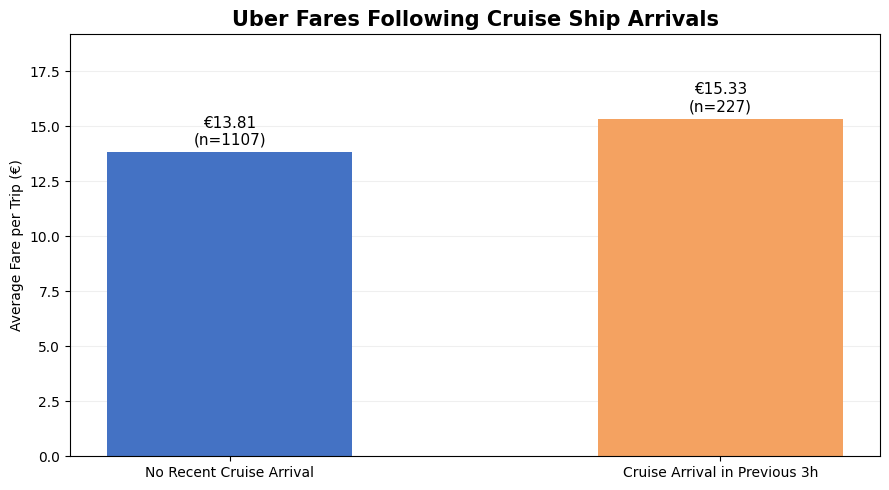

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    cruise_comparison.index,
    cruise_comparison['mean'],
    color=['#4472C4', '#F4A261'],
    width=0.5
)

for bar, count in zip(bars, cruise_comparison['count']):
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f'€{height:.2f}\n(n={int(count)})',
        ha='center',
        va='bottom',
        fontsize=11
    )

ax.set_title(
    'Uber Fares Following Cruise Ship Arrivals',
    fontsize=15,
    weight='bold'
)

ax.set_ylabel('Average Fare per Trip (€)')
ax.set_ylim(0, cruise_comparison['mean'].max() * 1.25)

ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('05_cruise_ship_impact.png', dpi=300, bbox_inches='tight')
plt.show()

#### Key Insight

Uber trips recorded within three hours following cruise ship arrivals had an average fare of €15.33, compared with €13.81 for trips without recent cruise arrivals. This represents an increase of approximately 11%.

This finding suggests a positive association between recent cruise ship arrivals and recorded Uber trip fares in Dubrovnik.

However, the exploratory analysis also revealed that trips following cruise arrivals tended to have longer durations. Consequently, higher average fares did not necessarily translate into greater fare-based earning efficiency per hour of completed trip time.

Cruise ship schedules may therefore provide useful supplementary information for driving decisions, but should not be considered an independent predictor of profitability.

These results are observational and do not establish that cruise ship arrivals directly caused higher fares.

## 6. Fare Efficiency Following Cruise Ship Arrivals

Comparison of recorded Uber fares per hour of completed trip time, with and without cruise ship arrivals in the preceding three hours.

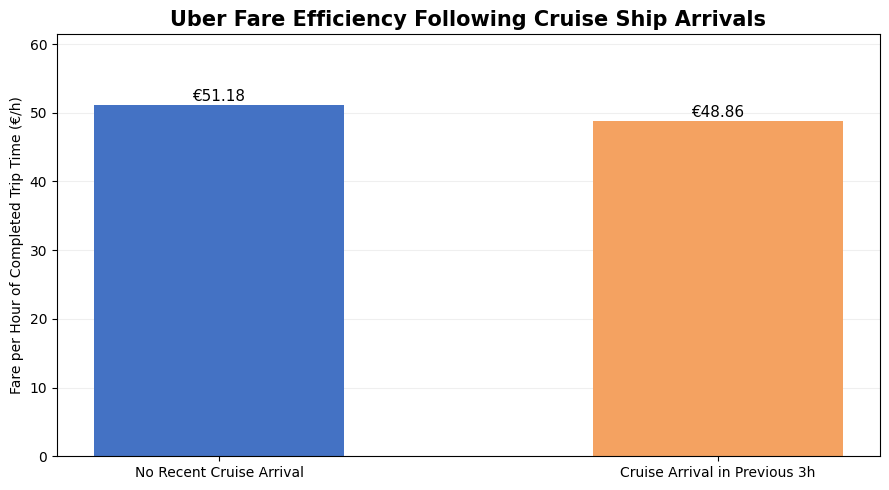

In [15]:
# Compare fare efficiency by recent cruise arrivals
df['recent_cruise_arrival'] = df['cruises_previous_3h'] > 0

fare_efficiency = (
    df.groupby('recent_cruise_arrival')
    .agg(
        total_fare=('original_fare', 'sum'),
        total_trip_minutes=('trip_duration_minutes', 'sum'),
        ride_count=('original_fare', 'size')
    )
)

fare_efficiency['fare_per_trip_hour'] = (
    fare_efficiency['total_fare'] /
    fare_efficiency['total_trip_minutes'] * 60
)

fare_efficiency = fare_efficiency.reindex([False, True])

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    ['No Recent Cruise Arrival', 'Cruise Arrival in Previous 3h'],
    fare_efficiency['fare_per_trip_hour'],
    color=['#4472C4', '#F4A261'],
    width=0.5
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f'€{height:.2f}',
        ha='center',
        fontsize=11
    )

ax.set_title(
    'Uber Fare Efficiency Following Cruise Ship Arrivals',
    fontsize=15,
    weight='bold'
)

ax.set_ylabel('Fare per Hour of Completed Trip Time (€/h)')
ax.set_ylim(0, fare_efficiency['fare_per_trip_hour'].max() * 1.2)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('06_cruise_fare_efficiency.png', dpi=300, bbox_inches='tight')
plt.show()

#### Key Insight

Although Uber trips following cruise ship arrivals had approximately 11% higher average fares, their fare efficiency was lower when adjusted for completed trip duration.

Trips without recent cruise arrivals generated €51.18 per hour of completed trip time, compared with €48.86 following cruise arrivals, representing approximately a 4.5% decrease.

This suggests that higher trip fares do not necessarily translate into greater time-adjusted earning efficiency, particularly when trips take longer to complete.

From a business perspective, optimizing driving schedules requires considering both fare values and the time required to complete trips, rather than focusing exclusively on higher-priced rides.

Important limitation: This metric represents recorded Uber fares per hour of completed trip time, not the driver’s actual hourly income or net profitability. It excludes waiting time, time spent between trips, platform commissions, fuel costs, and trips completed through other transportation services.